In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


**EMPLOYEE DATA**

In [ ]:
emp_info = pd.read_csv("/content/emp_info.csv")
emp_info

,emp_id,first_name,last_name,dob,gender,marital_status,qualification,city,state,country,hire_date,is_active
0,EMP001A,Olivia,Jones,13-02-1997,Female,Single,Bachelors,London,England,UK,27-11-2019,True
1,EMP002A,Anjali,Chauhan,06-02-1980,Male,Single,Diploma,Bangalore,Karnataka,India,19-08-2022,False
2,EMP003A,Elizabeth,Jones,25-02-1978,Female,Married,Masters,New York,New York,US,19-10-2017,True
3,EMP004A,Kavita,Sharma,08-07-1993,Female,Single,Bachelors,New Delhi,Delhi,India,22-03-2020,True
4,EMP005A,Jacob,Taylor,16-09-1993,Male,Married,Masters,Glasgow,Scotland,UK,28-06-2020,True
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,EMP006K,Poppy,Evans,30-04-1985,Male,Single,Diploma,Birmingham,England,UK,18-08-2017,True
9996,EMP007K,Jennifer,Davis,29-11-2002,Male,Married,Bachelors,Seattle,Washington,US,29-05-2020,False
9997,EMP008K,Rahul,Patel,04-10-1968,Male,Married,Masters,Bangalore,Karnataka,India,18-09-2015,False
9998,EMP009K,Michael,Garcia,11-04-1984,Male,Divorced,Masters,New York,New York,US,16-07-2017,True


In [ ]:
emp_info.head()

,emp_id,first_name,last_name,dob,gender,marital_status,qualification,city,state,country,hire_date,is_active
0,EMP001A,Olivia,Jones,13-02-1997,Female,Single,Bachelors,London,England,UK,27-11-2019,True
1,EMP002A,Anjali,Chauhan,06-02-1980,Male,Single,Diploma,Bangalore,Karnataka,India,19-08-2022,False
2,EMP003A,Elizabeth,Jones,25-02-1978,Female,Married,Masters,New York,New York,US,19-10-2017,True
3,EMP004A,Kavita,Sharma,08-07-1993,Female,Single,Bachelors,New Delhi,Delhi,India,22-03-2020,True
4,EMP005A,Jacob,Taylor,16-09-1993,Male,Married,Masters,Glasgow,Scotland,UK,28-06-2020,True


In [ ]:
emp_info.shape

(10000, 12)

In [ ]:
emp_info.columns

Index(['emp_id', 'first_name', 'last_name', 'dob', 'gender', 'marital_status',
       'qualification', 'city', 'state', 'country', 'hire_date', 'is_active'],
      dtype='object')

In [ ]:
emp_info.dtypes

,0
emp_id,object
first_name,object
last_name,object
dob,object
gender,object
marital_status,object
qualification,object
city,object
state,object
country,object


In [ ]:
emp_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   emp_id          10000 non-null  object
 1   first_name      10000 non-null  object
 2   last_name       10000 non-null  object
 3   dob             10000 non-null  object
 4   gender          10000 non-null  object
 5   marital_status  10000 non-null  object
 6   qualification   10000 non-null  object
 7   city            10000 non-null  object
 8   state           10000 non-null  object
 9   country         10000 non-null  object
 10  hire_date       10000 non-null  object
 11  is_active       10000 non-null  bool  
dtypes: bool(1), object(11)
memory usage: 869.3+ KB


In [ ]:
emp_info.describe()

,emp_id,first_name,last_name,dob,gender,marital_status,qualification,city,state,country,hire_date,is_active
count,10000,10000,10000,10000,10000,10000,10000,10000,10000,10000,10000,10000
unique,10000,39,31,7251,2,3,5,15,12,3,3872,2
top,EMP993J,Isla,Williams,12-05-1999,Female,Married,Bachelors,Chennai,England,India,03-04-2019,True
freq,1,308,729,7,5017,4972,4981,719,2017,3357,10,8488


In [ ]:
emp_info.nunique()

,0
emp_id,10000
first_name,39
last_name,31
dob,7251
gender,2
marital_status,3
qualification,5
city,15
state,12
country,3


In [ ]:
emp_info.duplicated().sum()

np.int64(0)

In [ ]:
emp_info.isnull().sum()

,0
emp_id,0
first_name,0
last_name,0
dob,0
gender,0
marital_status,0
qualification,0
city,0
state,0
country,0


In [ ]:
#Calculate missing-value percentages:
missing_percentage = (
emp_info.isnull().sum() / len(emp_info)
) * 100
missing_percentage.sort_values(
ascending=False
)

,0
emp_id,0.0
first_name,0.0
last_name,0.0
dob,0.0
gender,0.0
marital_status,0.0
qualification,0.0
city,0.0
state,0.0
country,0.0


In [ ]:
#Create a missing-value summary:
missing_summary = pd.DataFrame({
"Missing Values": emp_info.isnull().sum(),
"Missing Percentage": missing_percentage
})
missing_summary.sort_values(
by="Missing Percentage",
ascending=False
)

,Missing Values,Missing Percentage
emp_id,0,0.0
first_name,0,0.0
last_name,0,0.0
dob,0,0.0
gender,0,0.0
marital_status,0,0.0
qualification,0,0.0
city,0,0.0
state,0,0.0
country,0,0.0


In [ ]:
for data in [
    emp_info

]:
    data.columns = (
        data.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )

In [ ]:
emp_info["dob"].head()

,dob
0,13-02-1997
1,06-02-1980
2,25-02-1978
3,08-07-1993
4,16-09-1993


In [ ]:
emp_info["dob"].dtype

dtype('O')

In [ ]:
#Convert date of birth:
emp_info["dob"] = pd.to_datetime(
    emp_info["dob"],
    errors="coerce"
)


/tmp/ipykernel_1628/1570429169.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  emp_info["dob"] = pd.to_datetime(


In [ ]:
print(emp_info.columns.tolist())

['emp_id', 'first_name', 'last_name', 'dob', 'gender', 'marital_status', 'qualification', 'city', 'state', 'country', 'hire_date', 'is_active']


In [ ]:
emp_info["hire_date"].head()

,hire_date
0,27-11-2019
1,19-08-2022
2,19-10-2017
3,22-03-2020
4,28-06-2020


In [ ]:
emp_info["hire_date"].dtype

dtype('O')

In [ ]:
#Convert hire date:
emp_info["hire_date"] = pd.to_datetime(
    emp_info["hire_date"],
    errors="coerce"
)

/tmp/ipykernel_1628/454257606.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  emp_info["hire_date"] = pd.to_datetime(


In [ ]:
emp_info = emp_info.drop_duplicates()

In [ ]:
text_columns = [
    "gender",
    "marital_status",
    "qualification",
    "city",
    "is_active"
]

for column in text_columns:
    emp_info[column] = (
        emp_info[column]
        .astype("string")
        .str.strip()
    )

In [ ]:
emp_info["emp_id"].isnull().sum()

np.int64(0)

**SALARY DATA**

In [ ]:
emp_salaries = pd.read_csv("/content/emp_salary.csv")
emp_salaries

,emp_id,dept_id,role_id,year_of_exp,basic_salary,pf_deduction,esi_deduction,performace_rating,performance_bonus,gross_salary
0,EMP001A,DT1,JR03,7,27470.0,3296.4,0.0,4.7,1419.65,25593.25
1,EMP002A,DT4,JR14,4,120000.0,14400.0,0.0,3.4,4032.00,109632.00
2,EMP003A,DT7,JR15,9,130050.0,15606.0,0.0,4.7,22685.92,137129.92
3,EMP004A,DT7,JR03,6,27060.0,3247.2,0.0,4.2,3117.31,26930.11
4,EMP005A,DT7,JR06,6,41920.0,5030.4,0.0,5.0,1767.35,38656.95
...,...,...,...,...,...,...,...,...,...,...
9995,EMP006K,DT3,JR07,9,58000.0,6960.0,0.0,4.6,6890.40,57930.40
9996,EMP007K,DT5,JR10,6,144650.0,17358.0,0.0,4.2,4374.22,131666.22
9997,EMP008K,DT9,JR01,11,23250.0,2790.0,0.0,3.9,1125.30,21585.30
9998,EMP009K,DT8,JR15,9,130950.0,15714.0,0.0,4.7,18113.00,133349.00


In [ ]:
emp_salaries.head()

,emp_id,dept_id,role_id,year_of_exp,basic_salary,pf_deduction,esi_deduction,performace_rating,performance_bonus,gross_salary
0,EMP001A,DT1,JR03,7,27470.0,3296.4,0.0,4.7,1419.65,25593.25
1,EMP002A,DT4,JR14,4,120000.0,14400.0,0.0,3.4,4032.00,109632.00
2,EMP003A,DT7,JR15,9,130050.0,15606.0,0.0,4.7,22685.92,137129.92
3,EMP004A,DT7,JR03,6,27060.0,3247.2,0.0,4.2,3117.31,26930.11
4,EMP005A,DT7,JR06,6,41920.0,5030.4,0.0,5.0,1767.35,38656.95


In [ ]:
emp_salaries.shape

(10000, 10)

In [ ]:
emp_salaries.columns

Index(['emp_id', 'dept_id', 'role_id', 'year_of_exp', 'basic_salary',
       'pf_deduction', 'esi_deduction', 'performace_rating',
       'performance_bonus', 'gross_salary'],
      dtype='object')

In [ ]:
emp_salaries.dtypes

,0
emp_id,object
dept_id,object
role_id,object
year_of_exp,int64
basic_salary,float64
pf_deduction,float64
esi_deduction,float64
performace_rating,float64
performance_bonus,float64
gross_salary,float64


In [ ]:
emp_salaries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   emp_id             10000 non-null  object 
 1   dept_id            10000 non-null  object 
 2   role_id            10000 non-null  object 
 3   year_of_exp        10000 non-null  int64  
 4   basic_salary       10000 non-null  float64
 5   pf_deduction       10000 non-null  float64
 6   esi_deduction      10000 non-null  float64
 7   performace_rating  10000 non-null  float64
 8   performance_bonus  10000 non-null  float64
 9   gross_salary       10000 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 781.4+ KB


In [ ]:
emp_salaries.describe()

,year_of_exp,basic_salary,pf_deduction,esi_deduction,performace_rating,performance_bonus,gross_salary
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5.917100,79031.441750,9483.773010,8.781721,3.782470,6011.190014,75550.077033
std,3.389097,45297.012188,5435.641463,34.025728,0.985735,6429.342588,44477.662265
min,0.000000,15000.000000,1800.000000,0.000000,1.500000,0.000000,13087.500000
25%,3.000000,37440.000000,4492.800000,0.000000,2.900000,1476.567500,34913.307500
50%,6.000000,76675.000000,9201.000000,0.000000,4.100000,3716.160000,71765.690000
75%,9.000000,116450.000000,13974.000000,0.000000,4.500000,8231.967500,109426.960000
max,12.000000,190200.000000,22824.000000,157.500000,5.000000,40861.800000,207181.800000


In [ ]:
emp_salaries.nunique()

,0
emp_id,10000
dept_id,9
role_id,16
year_of_exp,13
basic_salary,1583
pf_deduction,1583
esi_deduction,114
performace_rating,36
performance_bonus,8686
gross_salary,9254


In [ ]:
emp_salaries.duplicated().sum()

np.int64(0)

In [ ]:
salary_missing_percentage = (
emp_salaries.isnull().sum() /
len(emp_salaries)
) * 100

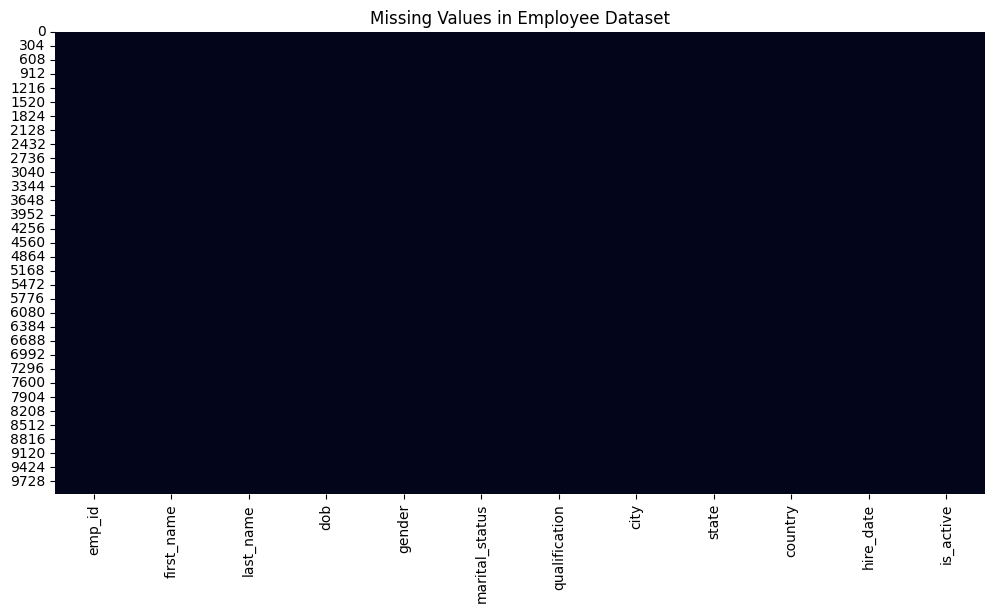

In [ ]:
#Visualize missing values:
plt.figure(figsize=(12, 6))
sns.heatmap(
emp_info.isnull(),
cbar=False
)
plt.title("Missing Values in Employee Dataset")
plt.show()

In [ ]:
for data in [

    emp_salaries

]:
    data.columns = (
        data.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )

In [ ]:
emp_salaries = emp_salaries.drop_duplicates()

In [ ]:
#Identify salary-related columns:
salary_columns = [
    "basic_salary",
    "pf_deduction",
    "esi_deduction",
    "performace_rating",
    "performance_bonus",
    "gross_salary"

]


In [ ]:
#Convert them to numeric:
for column in salary_columns:
    emp_salaries[column] = pd.to_numeric(
        emp_salaries[column],
        errors="coerce"
    )

In [ ]:
#Check Invalid Salaries
emp_salaries[
    (emp_salaries["basic_salary"] < 0) |
    (emp_salaries["gross_salary"] < 0)
]

,emp_id,dept_id,role_id,year_of_exp,basic_salary,pf_deduction,esi_deduction,performace_rating,performance_bonus,gross_salary


In [ ]:
 #Check Invalid Deductions
emp_salaries[
(emp_salaries["pf_deduction"] < 0) |
(emp_salaries["esi_deduction"] < 0)
]

,emp_id,dept_id,role_id,year_of_exp,basic_salary,pf_deduction,esi_deduction,performace_rating,performance_bonus,gross_salary


In [ ]:
#Check Invalid Performance Ratings
emp_salaries[
emp_salaries["performace_rating"] < 0
]

,emp_id,dept_id,role_id,year_of_exp,basic_salary,pf_deduction,esi_deduction,performace_rating,performance_bonus,gross_salary


In [ ]:
emp_salaries["emp_id"].isnull().sum()

np.int64(0)

In [ ]:
#The employee and salary tables can be joined using employee_id.
hr_data = emp_info.merge(
emp_salaries,
on="emp_id",
how="left"
)
hr_data

,emp_id,first_name,last_name,dob,gender,marital_status,qualification,city,state,country,...,is_active,dept_id,role_id,year_of_exp,basic_salary,pf_deduction,esi_deduction,performace_rating,performance_bonus,gross_salary
0,EMP001A,Olivia,Jones,1997-02-13,Female,Single,Bachelors,London,England,UK,...,True,DT1,JR03,7,27470.0,3296.4,0.0,4.7,1419.65,25593.25
1,EMP002A,Anjali,Chauhan,1980-02-06,Male,Single,Diploma,Bangalore,Karnataka,India,...,False,DT4,JR14,4,120000.0,14400.0,0.0,3.4,4032.00,109632.00
2,EMP003A,Elizabeth,Jones,1978-02-25,Female,Married,Masters,New York,New York,US,...,True,DT7,JR15,9,130050.0,15606.0,0.0,4.7,22685.92,137129.92
3,EMP004A,Kavita,Sharma,1993-07-08,Female,Single,Bachelors,New Delhi,Delhi,India,...,True,DT7,JR03,6,27060.0,3247.2,0.0,4.2,3117.31,26930.11
4,EMP005A,Jacob,Taylor,1993-09-16,Male,Married,Masters,Glasgow,Scotland,UK,...,True,DT7,JR06,6,41920.0,5030.4,0.0,5.0,1767.35,38656.95
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,EMP006K,Poppy,Evans,1985-04-30,Male,Single,Diploma,Birmingham,England,UK,...,True,DT3,JR07,9,58000.0,6960.0,0.0,4.6,6890.40,57930.40
9996,EMP007K,Jennifer,Davis,2002-11-29,Male,Married,Bachelors,Seattle,Washington,US,...,False,DT5,JR10,6,144650.0,17358.0,0.0,4.2,4374.22,131666.22
9997,EMP008K,Rahul,Patel,1968-10-04,Male,Married,Masters,Bangalore,Karnataka,India,...,False,DT9,JR01,11,23250.0,2790.0,0.0,3.9,1125.30,21585.30
9998,EMP009K,Michael,Garcia,1984-04-11,Male,Divorced,Masters,New York,New York,US,...,True,DT8,JR15,9,130950.0,15714.0,0.0,4.7,18113.00,133349.00


**Department Data**

In [ ]:
department = pd.read_csv("/content/department.csv")
department

,dept_id,dept_name,cost_center
0,DT1,Engineering,CC-2824
1,DT2,Sales,CC-1409
2,DT3,Marketing,CC-5506
3,DT4,HR,CC-5012
4,DT5,Finance,CC-4657
5,DT6,IT,CC-3286
6,DT7,Operations,CC-2679
7,DT8,Product,CC-9935
8,DT9,Customer Service,CC-2424


In [ ]:
department.head()

,dept_id,dept_name,cost_center
0,DT1,Engineering,CC-2824
1,DT2,Sales,CC-1409
2,DT3,Marketing,CC-5506
3,DT4,HR,CC-5012
4,DT5,Finance,CC-4657


In [ ]:
department.shape

(9, 3)

In [ ]:
department.columns

Index(['dept_id', 'dept_name', 'cost_center'], dtype='object')

In [ ]:
department.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   dept_id      9 non-null      object
 1   dept_name    9 non-null      object
 2   cost_center  9 non-null      object
dtypes: object(3)
memory usage: 348.0+ bytes


In [ ]:
department.nunique()

,0
dept_id,9
dept_name,9
cost_center,9


In [ ]:
for data in [

    department

]:
    data.columns = (
        data.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )

In [ ]:
department = department.drop_duplicates()

In [ ]:
department["dept_name"] = (
    department["dept_name"]
    .astype("string")
    .str.strip()
)
department

,dept_id,dept_name,cost_center
0,DT1,Engineering,CC-2824
1,DT2,Sales,CC-1409
2,DT3,Marketing,CC-5506
3,DT4,HR,CC-5012
4,DT5,Finance,CC-4657
5,DT6,IT,CC-3286
6,DT7,Operations,CC-2679
7,DT8,Product,CC-9935
8,DT9,Customer Service,CC-2424


In [ ]:
department["dept_id"].isnull().sum()

np.int64(0)

In [ ]:
#Join department information:
hr_data = hr_data.merge(
department,
on="dept_id",
how="left"
)
hr_data

,emp_id,first_name,last_name,dob,gender,marital_status,qualification,city,state,country,...,role_id,year_of_exp,basic_salary,pf_deduction,esi_deduction,performace_rating,performance_bonus,gross_salary,dept_name,cost_center
0,EMP001A,Olivia,Jones,1997-02-13,Female,Single,Bachelors,London,England,UK,...,JR03,7,27470.0,3296.4,0.0,4.7,1419.65,25593.25,Engineering,CC-2824
1,EMP002A,Anjali,Chauhan,1980-02-06,Male,Single,Diploma,Bangalore,Karnataka,India,...,JR14,4,120000.0,14400.0,0.0,3.4,4032.00,109632.00,HR,CC-5012
2,EMP003A,Elizabeth,Jones,1978-02-25,Female,Married,Masters,New York,New York,US,...,JR15,9,130050.0,15606.0,0.0,4.7,22685.92,137129.92,Operations,CC-2679
3,EMP004A,Kavita,Sharma,1993-07-08,Female,Single,Bachelors,New Delhi,Delhi,India,...,JR03,6,27060.0,3247.2,0.0,4.2,3117.31,26930.11,Operations,CC-2679
4,EMP005A,Jacob,Taylor,1993-09-16,Male,Married,Masters,Glasgow,Scotland,UK,...,JR06,6,41920.0,5030.4,0.0,5.0,1767.35,38656.95,Operations,CC-2679
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,EMP006K,Poppy,Evans,1985-04-30,Male,Single,Diploma,Birmingham,England,UK,...,JR07,9,58000.0,6960.0,0.0,4.6,6890.40,57930.40,Marketing,CC-5506
9996,EMP007K,Jennifer,Davis,2002-11-29,Male,Married,Bachelors,Seattle,Washington,US,...,JR10,6,144650.0,17358.0,0.0,4.2,4374.22,131666.22,Finance,CC-4657
9997,EMP008K,Rahul,Patel,1968-10-04,Male,Married,Masters,Bangalore,Karnataka,India,...,JR01,11,23250.0,2790.0,0.0,3.9,1125.30,21585.30,Customer Service,CC-2424
9998,EMP009K,Michael,Garcia,1984-04-11,Male,Divorced,Masters,New York,New York,US,...,JR15,9,130950.0,15714.0,0.0,4.7,18113.00,133349.00,Product,CC-9935


**Job role Data**

In [ ]:
job_roles = pd.read_csv("/content/job_roles.csv")
job_roles


,role_id,position,base_salary
0,JR01,Data Entry Operator,15000
1,JR02,Customer Support Executive,18000
2,JR03,Office Administrator,20500
3,JR04,IT Support Specialist,28000
4,JR05,HR Generalist,35000
5,JR06,Sales Executive,32000
6,JR07,Marketing Specialist,40000
7,JR08,Data Analyst,55000
8,JR09,Software Engineer,70000
9,JR10,Senior Software Engineer,110000


In [ ]:
job_roles.head()

,role_id,position,base_salary
0,JR01,Data Entry Operator,15000
1,JR02,Customer Support Executive,18000
2,JR03,Office Administrator,20500
3,JR04,IT Support Specialist,28000
4,JR05,HR Generalist,35000


In [ ]:
job_roles.shape

(16, 3)

In [ ]:
job_roles.columns

Index(['role_id', 'position', 'base_salary'], dtype='object')

In [ ]:
job_roles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   role_id      16 non-null     object
 1   position     16 non-null     object
 2   base_salary  16 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 516.0+ bytes


In [ ]:
job_roles.nunique()

,0
role_id,16
position,16
base_salary,15


In [ ]:
for data in [

    job_roles
]:
    data.columns = (
        data.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )

In [ ]:
job_roles = job_roles.drop_duplicates()

In [ ]:
job_roles["position"] = (
    job_roles["position"]
    .astype("string")
    .str.strip()
)
job_roles

,role_id,position,base_salary
0,JR01,Data Entry Operator,15000
1,JR02,Customer Support Executive,18000
2,JR03,Office Administrator,20500
3,JR04,IT Support Specialist,28000
4,JR05,HR Generalist,35000
5,JR06,Sales Executive,32000
6,JR07,Marketing Specialist,40000
7,JR08,Data Analyst,55000
8,JR09,Software Engineer,70000
9,JR10,Senior Software Engineer,110000


In [ ]:
#Convert salary benchmark:
job_roles["base_salary"] = pd.to_numeric(
job_roles["base_salary"],
errors="coerce"
)

In [ ]:
job_roles["role_id"].isnull().sum()

np.int64(0)

In [ ]:
#Join job role information:
hr_data = hr_data.merge(
job_roles,
on="role_id",
how="left"
)
hr_data

,emp_id,first_name,last_name,dob,gender,marital_status,qualification,city,state,country,...,basic_salary,pf_deduction,esi_deduction,performace_rating,performance_bonus,gross_salary,dept_name,cost_center,position,base_salary
0,EMP001A,Olivia,Jones,1997-02-13,Female,Single,Bachelors,London,England,UK,...,27470.0,3296.4,0.0,4.7,1419.65,25593.25,Engineering,CC-2824,Office Administrator,20500
1,EMP002A,Anjali,Chauhan,1980-02-06,Male,Single,Diploma,Bangalore,Karnataka,India,...,120000.0,14400.0,0.0,3.4,4032.00,109632.00,HR,CC-5012,Finance Manager,100000
2,EMP003A,Elizabeth,Jones,1978-02-25,Female,Married,Masters,New York,New York,US,...,130050.0,15606.0,0.0,4.7,22685.92,137129.92,Operations,CC-2679,Sales Manager,90000
3,EMP004A,Kavita,Sharma,1993-07-08,Female,Single,Bachelors,New Delhi,Delhi,India,...,27060.0,3247.2,0.0,4.2,3117.31,26930.11,Operations,CC-2679,Office Administrator,20500
4,EMP005A,Jacob,Taylor,1993-09-16,Male,Married,Masters,Glasgow,Scotland,UK,...,41920.0,5030.4,0.0,5.0,1767.35,38656.95,Operations,CC-2679,Sales Executive,32000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,EMP006K,Poppy,Evans,1985-04-30,Male,Single,Diploma,Birmingham,England,UK,...,58000.0,6960.0,0.0,4.6,6890.40,57930.40,Marketing,CC-5506,Marketing Specialist,40000
9996,EMP007K,Jennifer,Davis,2002-11-29,Male,Married,Bachelors,Seattle,Washington,US,...,144650.0,17358.0,0.0,4.2,4374.22,131666.22,Finance,CC-4657,Senior Software Engineer,110000
9997,EMP008K,Rahul,Patel,1968-10-04,Male,Married,Masters,Bangalore,Karnataka,India,...,23250.0,2790.0,0.0,3.9,1125.30,21585.30,Customer Service,CC-2424,Data Entry Operator,15000
9998,EMP009K,Michael,Garcia,1984-04-11,Male,Divorced,Masters,New York,New York,US,...,130950.0,15714.0,0.0,4.7,18113.00,133349.00,Product,CC-9935,Sales Manager,90000


In [ ]:
#Check the final dataset:
hr_data.head()


,emp_id,first_name,last_name,dob,gender,marital_status,qualification,city,state,country,...,basic_salary,pf_deduction,esi_deduction,performace_rating,performance_bonus,gross_salary,dept_name,cost_center,position,base_salary
0,EMP001A,Olivia,Jones,1997-02-13,Female,Single,Bachelors,London,England,UK,...,27470.0,3296.4,0.0,4.7,1419.65,25593.25,Engineering,CC-2824,Office Administrator,20500
1,EMP002A,Anjali,Chauhan,1980-02-06,Male,Single,Diploma,Bangalore,Karnataka,India,...,120000.0,14400.0,0.0,3.4,4032.00,109632.00,HR,CC-5012,Finance Manager,100000
2,EMP003A,Elizabeth,Jones,1978-02-25,Female,Married,Masters,New York,New York,US,...,130050.0,15606.0,0.0,4.7,22685.92,137129.92,Operations,CC-2679,Sales Manager,90000
3,EMP004A,Kavita,Sharma,1993-07-08,Female,Single,Bachelors,New Delhi,Delhi,India,...,27060.0,3247.2,0.0,4.2,3117.31,26930.11,Operations,CC-2679,Office Administrator,20500
4,EMP005A,Jacob,Taylor,1993-09-16,Male,Married,Masters,Glasgow,Scotland,UK,...,41920.0,5030.4,0.0,5.0,1767.35,38656.95,Operations,CC-2679,Sales Executive,32000


In [ ]:

hr_data.shape


(10000, 25)

In [ ]:

hr_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   emp_id             10000 non-null  object        
 1   first_name         10000 non-null  object        
 2   last_name          10000 non-null  object        
 3   dob                10000 non-null  datetime64[ns]
 4   gender             10000 non-null  string        
 5   marital_status     10000 non-null  string        
 6   qualification      10000 non-null  string        
 7   city               10000 non-null  string        
 8   state              10000 non-null  object        
 9   country            10000 non-null  object        
 10  hire_date          10000 non-null  datetime64[ns]
 11  is_active          10000 non-null  string        
 12  dept_id            10000 non-null  object        
 13  role_id            10000 non-null  object        
 14  year_of

** Feature Engineering **

In [ ]:
 #Extract Hire Year
hr_data["hire_year"] = (
hr_data["hire_date"].dt.year
)

In [ ]:
 #Extract Hire Month
hr_data["hire_month"] = (
hr_data["hire_date"].dt.month
)

In [ ]:
 #Extract Hire Month Name
hr_data["hire_month_name"] = (
hr_data["hire_date"].dt.month_name()
)

In [ ]:
#Extract Hire Quarter
hr_data["hire_quarter"] = (
hr_data["hire_date"].dt.quarter
)

In [ ]:
#Calculate Salary After Deductions
#If gross salary and deductions are available:
hr_data["calculated_net_salary"] = (
hr_data["gross_salary"] -
hr_data["pf_deduction"] -
hr_data["esi_deduction"]
)
hr_data

,emp_id,first_name,last_name,dob,gender,marital_status,qualification,city,state,country,...,gross_salary,dept_name,cost_center,position,base_salary,hire_year,hire_month,hire_month_name,hire_quarter,calculated_net_salary
0,EMP001A,Olivia,Jones,1997-02-13,Female,Single,Bachelors,London,England,UK,...,25593.25,Engineering,CC-2824,Office Administrator,20500,2019,11,November,4,22296.85
1,EMP002A,Anjali,Chauhan,1980-02-06,Male,Single,Diploma,Bangalore,Karnataka,India,...,109632.00,HR,CC-5012,Finance Manager,100000,2022,8,August,3,95232.00
2,EMP003A,Elizabeth,Jones,1978-02-25,Female,Married,Masters,New York,New York,US,...,137129.92,Operations,CC-2679,Sales Manager,90000,2017,10,October,4,121523.92
3,EMP004A,Kavita,Sharma,1993-07-08,Female,Single,Bachelors,New Delhi,Delhi,India,...,26930.11,Operations,CC-2679,Office Administrator,20500,2020,3,March,1,23682.91
4,EMP005A,Jacob,Taylor,1993-09-16,Male,Married,Masters,Glasgow,Scotland,UK,...,38656.95,Operations,CC-2679,Sales Executive,32000,2020,6,June,2,33626.55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,EMP006K,Poppy,Evans,1985-04-30,Male,Single,Diploma,Birmingham,England,UK,...,57930.40,Marketing,CC-5506,Marketing Specialist,40000,2017,8,August,3,50970.40
9996,EMP007K,Jennifer,Davis,2002-11-29,Male,Married,Bachelors,Seattle,Washington,US,...,131666.22,Finance,CC-4657,Senior Software Engineer,110000,2020,5,May,2,114308.22
9997,EMP008K,Rahul,Patel,1968-10-04,Male,Married,Masters,Bangalore,Karnataka,India,...,21585.30,Customer Service,CC-2424,Data Entry Operator,15000,2015,9,September,3,18795.30
9998,EMP009K,Michael,Garcia,1984-04-11,Male,Divorced,Masters,New York,New York,US,...,133349.00,Product,CC-9935,Sales Manager,90000,2017,7,July,3,117635.00


In [ ]:
#Calculate Total Deductions
hr_data["total_deductions"] = (
hr_data["pf_deduction"] +
hr_data["esi_deduction"]
)
hr_data

,emp_id,first_name,last_name,dob,gender,marital_status,qualification,city,state,country,...,dept_name,cost_center,position,base_salary,hire_year,hire_month,hire_month_name,hire_quarter,calculated_net_salary,total_deductions
0,EMP001A,Olivia,Jones,1997-02-13,Female,Single,Bachelors,London,England,UK,...,Engineering,CC-2824,Office Administrator,20500,2019,11,November,4,22296.85,3296.4
1,EMP002A,Anjali,Chauhan,1980-02-06,Male,Single,Diploma,Bangalore,Karnataka,India,...,HR,CC-5012,Finance Manager,100000,2022,8,August,3,95232.00,14400.0
2,EMP003A,Elizabeth,Jones,1978-02-25,Female,Married,Masters,New York,New York,US,...,Operations,CC-2679,Sales Manager,90000,2017,10,October,4,121523.92,15606.0
3,EMP004A,Kavita,Sharma,1993-07-08,Female,Single,Bachelors,New Delhi,Delhi,India,...,Operations,CC-2679,Office Administrator,20500,2020,3,March,1,23682.91,3247.2
4,EMP005A,Jacob,Taylor,1993-09-16,Male,Married,Masters,Glasgow,Scotland,UK,...,Operations,CC-2679,Sales Executive,32000,2020,6,June,2,33626.55,5030.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,EMP006K,Poppy,Evans,1985-04-30,Male,Single,Diploma,Birmingham,England,UK,...,Marketing,CC-5506,Marketing Specialist,40000,2017,8,August,3,50970.40,6960.0
9996,EMP007K,Jennifer,Davis,2002-11-29,Male,Married,Bachelors,Seattle,Washington,US,...,Finance,CC-4657,Senior Software Engineer,110000,2020,5,May,2,114308.22,17358.0
9997,EMP008K,Rahul,Patel,1968-10-04,Male,Married,Masters,Bangalore,Karnataka,India,...,Customer Service,CC-2424,Data Entry Operator,15000,2015,9,September,3,18795.30,2790.0
9998,EMP009K,Michael,Garcia,1984-04-11,Male,Divorced,Masters,New York,New York,US,...,Product,CC-9935,Sales Manager,90000,2017,7,July,3,117635.00,15714.0


In [ ]:
# Calculate Salary Difference from Benchmark
hr_data["salary_vs_benchmark"] = (
hr_data["basic_salary"] -
hr_data["basic_salary"]
)
hr_data

,emp_id,first_name,last_name,dob,gender,marital_status,qualification,city,state,country,...,cost_center,position,base_salary,hire_year,hire_month,hire_month_name,hire_quarter,calculated_net_salary,total_deductions,salary_vs_benchmark
0,EMP001A,Olivia,Jones,1997-02-13,Female,Single,Bachelors,London,England,UK,...,CC-2824,Office Administrator,20500,2019,11,November,4,22296.85,3296.4,0.0
1,EMP002A,Anjali,Chauhan,1980-02-06,Male,Single,Diploma,Bangalore,Karnataka,India,...,CC-5012,Finance Manager,100000,2022,8,August,3,95232.00,14400.0,0.0
2,EMP003A,Elizabeth,Jones,1978-02-25,Female,Married,Masters,New York,New York,US,...,CC-2679,Sales Manager,90000,2017,10,October,4,121523.92,15606.0,0.0
3,EMP004A,Kavita,Sharma,1993-07-08,Female,Single,Bachelors,New Delhi,Delhi,India,...,CC-2679,Office Administrator,20500,2020,3,March,1,23682.91,3247.2,0.0
4,EMP005A,Jacob,Taylor,1993-09-16,Male,Married,Masters,Glasgow,Scotland,UK,...,CC-2679,Sales Executive,32000,2020,6,June,2,33626.55,5030.4,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,EMP006K,Poppy,Evans,1985-04-30,Male,Single,Diploma,Birmingham,England,UK,...,CC-5506,Marketing Specialist,40000,2017,8,August,3,50970.40,6960.0,0.0
9996,EMP007K,Jennifer,Davis,2002-11-29,Male,Married,Bachelors,Seattle,Washington,US,...,CC-4657,Senior Software Engineer,110000,2020,5,May,2,114308.22,17358.0,0.0
9997,EMP008K,Rahul,Patel,1968-10-04,Male,Married,Masters,Bangalore,Karnataka,India,...,CC-2424,Data Entry Operator,15000,2015,9,September,3,18795.30,2790.0,0.0
9998,EMP009K,Michael,Garcia,1984-04-11,Male,Divorced,Masters,New York,New York,US,...,CC-9935,Sales Manager,90000,2017,7,July,3,117635.00,15714.0,0.0


In [ ]:
 #Calculate Total Compensation
#If gross salary and performance bonus are separate:
hr_data["total_compensation"] = (
hr_data["gross_salary"] +
hr_data["performance_bonus"]
)
hr_data

,emp_id,first_name,last_name,dob,gender,marital_status,qualification,city,state,country,...,position,base_salary,hire_year,hire_month,hire_month_name,hire_quarter,calculated_net_salary,total_deductions,salary_vs_benchmark,total_compensation
0,EMP001A,Olivia,Jones,1997-02-13,Female,Single,Bachelors,London,England,UK,...,Office Administrator,20500,2019,11,November,4,22296.85,3296.4,0.0,27012.90
1,EMP002A,Anjali,Chauhan,1980-02-06,Male,Single,Diploma,Bangalore,Karnataka,India,...,Finance Manager,100000,2022,8,August,3,95232.00,14400.0,0.0,113664.00
2,EMP003A,Elizabeth,Jones,1978-02-25,Female,Married,Masters,New York,New York,US,...,Sales Manager,90000,2017,10,October,4,121523.92,15606.0,0.0,159815.84
3,EMP004A,Kavita,Sharma,1993-07-08,Female,Single,Bachelors,New Delhi,Delhi,India,...,Office Administrator,20500,2020,3,March,1,23682.91,3247.2,0.0,30047.42
4,EMP005A,Jacob,Taylor,1993-09-16,Male,Married,Masters,Glasgow,Scotland,UK,...,Sales Executive,32000,2020,6,June,2,33626.55,5030.4,0.0,40424.30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,EMP006K,Poppy,Evans,1985-04-30,Male,Single,Diploma,Birmingham,England,UK,...,Marketing Specialist,40000,2017,8,August,3,50970.40,6960.0,0.0,64820.80
9996,EMP007K,Jennifer,Davis,2002-11-29,Male,Married,Bachelors,Seattle,Washington,US,...,Senior Software Engineer,110000,2020,5,May,2,114308.22,17358.0,0.0,136040.44
9997,EMP008K,Rahul,Patel,1968-10-04,Male,Married,Masters,Bangalore,Karnataka,India,...,Data Entry Operator,15000,2015,9,September,3,18795.30,2790.0,0.0,22710.60
9998,EMP009K,Michael,Garcia,1984-04-11,Male,Divorced,Masters,New York,New York,US,...,Sales Manager,90000,2017,7,July,3,117635.00,15714.0,0.0,151462.00


In [ ]:
hr_data.columns

Index(['emp_id', 'first_name', 'last_name', 'dob', 'gender', 'marital_status',
       'qualification', 'city', 'state', 'country', 'hire_date', 'is_active',
       'dept_id', 'role_id', 'year_of_exp', 'basic_salary', 'pf_deduction',
       'esi_deduction', 'performace_rating', 'performance_bonus',
       'gross_salary', 'dept_name', 'cost_center', 'position', 'base_salary',
       'hire_year', 'hire_month', 'hire_month_name', 'hire_quarter',
       'calculated_net_salary', 'total_deductions', 'salary_vs_benchmark',
       'total_compensation'],
      dtype='object')

In [ ]:
 #Basic Dataset Analysis
# Total Employees
total_employees = (
hr_data["emp_id"].nunique()
)
total_employees

10000

In [ ]:
#Total Departments
total_departments = (
hr_data["dept_id"].nunique()
)
total_departments

9

In [ ]:
 #Total Job Roles
total_job_roles = (
hr_data["role_id"].nunique()
)
total_job_roles

16

In [ ]:
#Total Locations
total_locations = (
hr_data["city"].nunique()
)
total_locations

15

In [ ]:
#Total Locations
total_locations = (
hr_data["state"].nunique()
)
total_locations

12

In [ ]:
#Total Locations
total_locations = (
hr_data["country"].nunique()
)
total_locations

3

In [ ]:
# Active Employees
active_employees = hr_data[
hr_data["is_active"]
    .str.lower() == "active"
]

active_employees_count = (
    active_employees["emp_id"]
    .nunique()
)

active_employees_count

0

#Workforce Analysis

In [ ]:
 #Employees by Department
employees_by_department = (
    hr_data["dept_id"]
    .value_counts()
    .reset_index()
)

employees_by_department.columns = [
    "department",
    "employee_count"
]

employees_by_department

,department,employee_count
0,DT8,1166
1,DT1,1131
2,DT2,1128
3,DT7,1115
4,DT5,1113
5,DT6,1109
6,DT4,1092
7,DT9,1079
8,DT3,1067


In [ ]:
 #Employees by Location
employees_by_location = (
    hr_data["city"]
    .value_counts()
    .reset_index()
)

employees_by_location.columns = [
    "location",
    "employee_count"
]

employees_by_location


,location,employee_count
0,Chennai,719
1,Edinburgh,693
2,Birmingham,693
3,San Francisco,691
4,London,680
5,New Delhi,669
6,Seattle,667
7,Chicago,665
8,Mumbai,662
9,Hyderabad,654


In [ ]:
 #Employees by Location
employees_by_location = (
    hr_data["state"]
    .value_counts()
    .reset_index()
)

employees_by_location.columns = [
    "location",
    "employee_count"
]

employees_by_location


,location,employee_count
0,England,2017
1,Scotland,1331
2,Tamil Nadu,719
3,California,691
4,Delhi,669
5,Washington,667
6,Illinois,665
7,Maharashtra,662
8,Telangana,654
9,Karnataka,653


In [ ]:
 #Employees by Location
employees_by_location = (
    hr_data["country"]
    .value_counts()
    .reset_index()
)

employees_by_location.columns = [
    "location",
    "employee_count"
]

employees_by_location


,location,employee_count
0,India,3357
1,UK,3348
2,US,3295


In [ ]:
 #Employees by Gender
gender_distribution = (
    hr_data["gender"]
    .value_counts()
    .reset_index()
)

gender_distribution.columns = [
    "gender",
    "employee_count"
]

gender_distribution

,gender,employee_count
0,Female,5017
1,Male,4983


In [ ]:
 #Employees by Qualification
qualification_distribution = (
    hr_data["qualification"]
    .value_counts()
    .reset_index()
)

qualification_distribution.columns = [
    "qualification",
    "employee_count"
]

qualification_distribution

,qualification,employee_count
0,Bachelors,4981
1,Masters,2981
2,Diploma,1060
3,PhD,505
4,High School,473


In [ ]:
 #Employees by Marital Status
marital_distribution = (
    hr_data["marital_status"]
    .value_counts()
    .reset_index()
)

marital_distribution.columns = [
    "marital_status",
    "employee_count"
]

marital_distribution

,marital_status,employee_count
0,Married,4972
1,Single,4065
2,Divorced,963


In [ ]:
# Active Status Distribution
status_distribution = (
    hr_data["is_active"]
    .value_counts()
    .reset_index()
)

status_distribution.columns = [
    "status",
    "employee_count"
]

status_distribution

,status,employee_count
0,True,8488
1,False,1512


In [ ]:
#Active Employee Percentage
active_percentage = (
    active_employees_count /
    total_employees
) * 100

active_percentage

0.0

In [ ]:
#Active Employees by Department
active_by_department = (
    hr_data[
        hr_data["is_active"]
        .str.lower() == "active"
    ]
    .groupby("dept_id")
    ["emp_id"]
    .nunique()
    .reset_index(name="active_employees")
)

active_by_department

,dept_id,active_employees


  **Hiring trend analysis**

In [ ]:
#Employees Hired by Year
hiring_trend = (
    hr_data.groupby("hire_year")
    ["emp_id"]
    .nunique()
    .reset_index(name="employees_hired")
)

hiring_trend

,hire_year,employees_hired
0,2015,822
1,2016,894
2,2017,903
3,2018,901
4,2019,865
5,2020,867
6,2021,827
7,2022,782
8,2023,848
9,2024,867


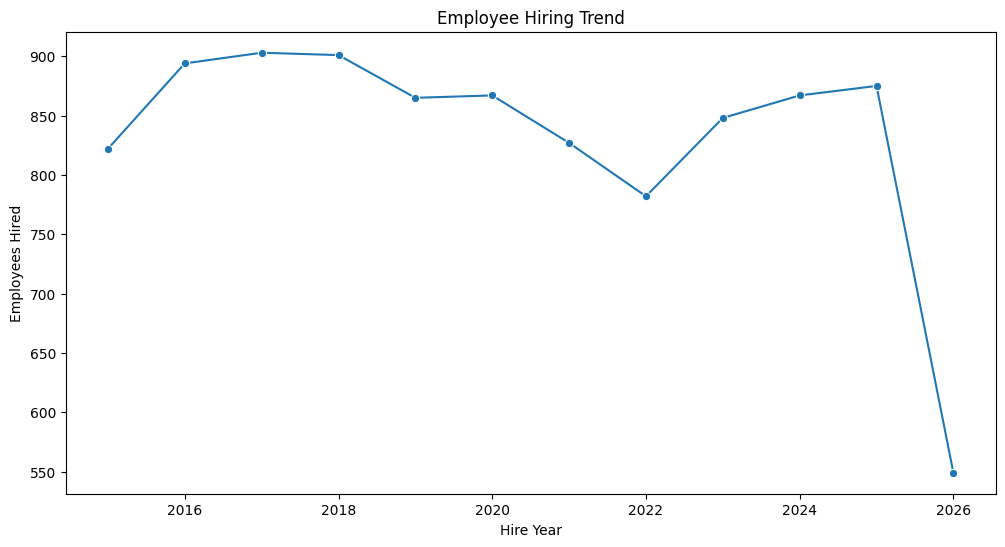

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hiring_trend,
    x="hire_year",
    y="employees_hired",
    marker="o"
)

plt.title("Employee Hiring Trend")
plt.xlabel("Hire Year")
plt.ylabel("Employees Hired")
plt.show()

#Department Analysis

In [ ]:
#Department Employee Count
department_employee_count = (
    hr_data.groupby("dept_name")
    ["emp_id"]
    .nunique()
    .sort_values(ascending=False)
)

department_employee_count

,emp_id
dept_name,
Product,1166
Engineering,1131
Sales,1128
Operations,1115
Finance,1113
IT,1109
HR,1092
Customer Service,1079
Marketing,1067


**Average Salary by Department**

In [ ]:
department_salary = (
    hr_data.groupby("dept_name")
    ["basic_salary"]
    .mean()
    .sort_values(ascending=False)
)

department_salary

,basic_salary
dept_name,
Customer Service,80398.776645
IT,79496.039225
Operations,79385.114350
Engineering,79302.864721
Finance,79216.379155
Marketing,79209.899250
Sales,78947.577571
HR,78788.967491
Product,76691.144940


**Average Net Salary by Department**

In [ ]:
department_net_salary = (
    hr_data.groupby("dept_name")
    ["calculated_net_salary"]
    .mean()
    .sort_values(ascending=False)
)

department_net_salary

,calculated_net_salary
dept_name,
Customer Service,67252.825533
IT,66489.377556
Operations,66476.467857
Finance,66233.386640
Engineering,66072.869010
Marketing,66031.525173
Sales,65960.116285
HR,65853.571639
Product,64266.312144


In [ ]:
#Total Payroll by Department
department_payroll = (
    hr_data.groupby("dept_name")
    ["gross_salary"]
    .sum()
    .sort_values(ascending=False)
)

department_payroll

,gross_salary
dept_name,
Product,85677293.41
Engineering,85502096.29
Sales,85099021.03
Operations,84754012.92
IT,84326170.26
Finance,84306493.97
Customer Service,82984096.87
HR,82244143.88
Marketing,80607441.70


In [ ]:
#Performance by Department
department_performance = (
    hr_data.groupby("dept_name")
    ["performace_rating"]
    .mean()
    .sort_values(ascending=False)
)

department_performance

,performace_rating
dept_name,
HR,3.827106
Customer Service,3.806487
Product,3.801458
IT,3.785122
Operations,3.782422
Engineering,3.777454
Sales,3.766046
Finance,3.756604
Marketing,3.738707


#Department Salary Visualization

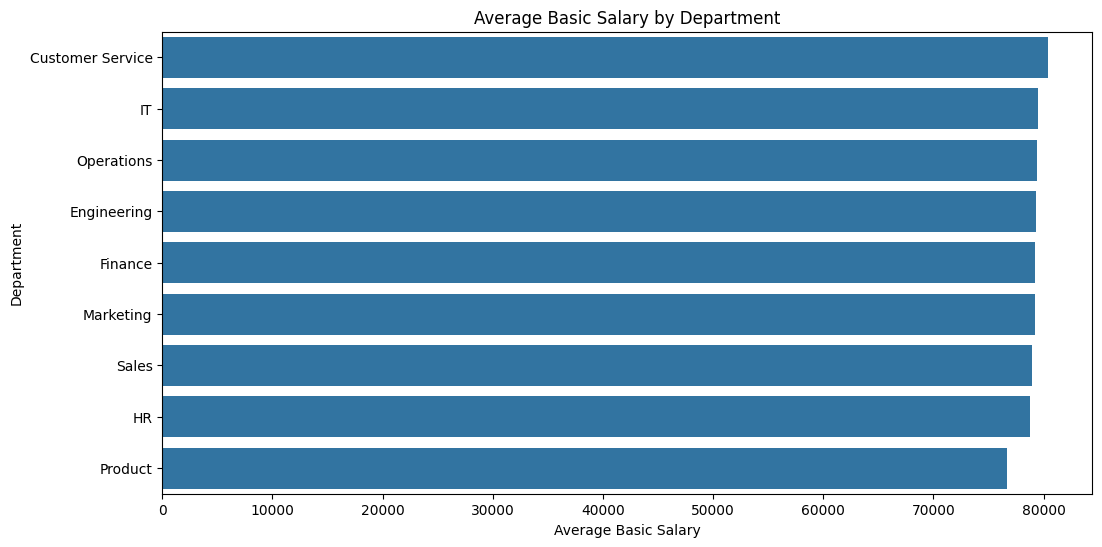

In [ ]:
department_salary_df = (
    department_salary
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=department_salary_df,
    x="basic_salary",
    y="dept_name"
)

plt.title("Average Basic Salary by Department")
plt.xlabel("Average Basic Salary")
plt.ylabel("Department")
plt.show()

#Job Role Analysis

In [ ]:
#Employees by Job Role
role_employee_count = (
    hr_data["position"]
    .value_counts()
    .reset_index()
)

role_employee_count.columns = [
    "position",
    "employee_count"
]

role_employee_count

,position,employee_count
0,Senior Software Engineer,714
1,HR Manager,670
2,Data Entry Operator,659
3,Marketing Specialist,648
4,IT Support Specialist,639
5,Finance Manager,633
6,Sales Executive,626
7,Financial Analyst,624
8,Product Manager,624
9,Office Administrator,618


In [ ]:
#Average Salary by Job Role
role_salary = (
    hr_data.groupby("position")
    ["basic_salary"]
    .mean()
    .sort_values(ascending=False)
)

role_salary


,basic_salary
position,
Product Manager,154575.961538
Senior Software Engineer,140978.711485
Finance Manager,129349.131122
Sales Manager,116353.079417
HR Manager,109850.447761
Operations Manager,109692.985318
Software Engineer,91378.330523
Financial Analyst,83407.291667
Data Analyst,71581.022530


In [ ]:
#Salary Benchmark by Job Role
role_benchmark = (
    hr_data.groupby("position")
    ["base_salary"]
    .mean()
    .sort_values(ascending=False)
)

role_benchmark

,base_salary
position,
Product Manager,120000.0
Senior Software Engineer,110000.0
Finance Manager,100000.0
Sales Manager,90000.0
Operations Manager,85000.0
HR Manager,85000.0
Software Engineer,70000.0
Financial Analyst,65000.0
Data Analyst,55000.0


In [ ]:
#Performance by Job Role
role_performance = (
    hr_data.groupby("position")
    ["performace_rating"]
    .mean()
    .sort_values(ascending=False)
)

role_performance

,performace_rating
position,
Software Engineer,3.896121
Office Administrator,3.836084
Marketing Specialist,3.834414
Data Entry Operator,3.807587
HR Generalist,3.799823
IT Support Specialist,3.790141
Data Analyst,3.789255
Finance Manager,3.787046
Operations Manager,3.786786


#Salary and Compensation Analysis

In [ ]:
#Basic Salary Statistics
hr_data[
    ["basic_salary"]
].describe()

,basic_salary
count,10000.000000
mean,79031.441750
std,45297.012188
min,15000.000000
25%,37440.000000
50%,76675.000000
75%,116450.000000
max,190200.000000


In [ ]:
#|Gross Salary Statistics
hr_data[
    ["gross_salary"]
].describe()

,gross_salary
count,10000.000000
mean,75550.077033
std,44477.662265
min,13087.500000
25%,34913.307500
50%,71765.690000
75%,109426.960000
max,207181.800000


In [ ]:
#Net Salary Statistics
hr_data[
    ["calculated_net_salary"]
].describe()

,calculated_net_salary
count,10000.000000
mean,66057.522302
std,39088.650095
min,11175.000000
25%,30403.915000
50%,62606.215000
75%,95544.477500
max,184501.800000


In [ ]:
#Average Performance Bonus
average_bonus = (
    hr_data["performance_bonus"]
    .mean()
)

average_bonus

np.float64(6011.190014)

In [ ]:
#Total Performance Bonus
total_bonus = (
    hr_data["performance_bonus"]
    .sum()
)

total_bonus

np.float64(60111900.14)

In [ ]:
#Total Payroll
total_payroll = (
    hr_data["gross_salary"]
    .sum()
)

total_payroll

np.float64(755500770.33)

In [ ]:
#Total Net Salary
total_net_salary = (
    hr_data["calculated_net_salary"]
    .sum()
)

total_net_salary

np.float64(660575223.02)

#Salary Benchmark Analysis

In [ ]:
benchmark_analysis = hr_data[
    [
        "emp_id",
        "position",
        "basic_salary",
        "base_salary",
        "salary_vs_benchmark"
    ]
]

benchmark_analysis.head()

#Employees above benchmark:
above_benchmark = hr_data[
    hr_data["salary_vs_benchmark"] > 0
]

above_benchmark.shape

#Employees below benchmark:
below_benchmark = hr_data[
    hr_data["salary_vs_benchmark"] < 0
]

below_benchmark.shape

#Average salary difference by role:
role_salary_difference = (
    hr_data.groupby("position")
    ["salary_vs_benchmark"]
    .mean()
    .sort_values(ascending=False)
)

role_salary_difference

,salary_vs_benchmark
position,
Customer Support Executive,0.0
Data Analyst,0.0
Data Entry Operator,0.0
Finance Manager,0.0
Financial Analyst,0.0
HR Generalist,0.0
HR Manager,0.0
IT Support Specialist,0.0
Marketing Specialist,0.0


#Deduction Analysis

In [ ]:
hr_data

,emp_id,first_name,last_name,dob,gender,marital_status,qualification,city,state,country,...,position,base_salary,hire_year,hire_month,hire_month_name,hire_quarter,calculated_net_salary,total_deductions,salary_vs_benchmark,total_compensation
0,EMP001A,Olivia,Jones,1997-02-13,Female,Single,Bachelors,London,England,UK,...,Office Administrator,20500,2019,11,November,4,22296.85,3296.4,0.0,27012.90
1,EMP002A,Anjali,Chauhan,1980-02-06,Male,Single,Diploma,Bangalore,Karnataka,India,...,Finance Manager,100000,2022,8,August,3,95232.00,14400.0,0.0,113664.00
2,EMP003A,Elizabeth,Jones,1978-02-25,Female,Married,Masters,New York,New York,US,...,Sales Manager,90000,2017,10,October,4,121523.92,15606.0,0.0,159815.84
3,EMP004A,Kavita,Sharma,1993-07-08,Female,Single,Bachelors,New Delhi,Delhi,India,...,Office Administrator,20500,2020,3,March,1,23682.91,3247.2,0.0,30047.42
4,EMP005A,Jacob,Taylor,1993-09-16,Male,Married,Masters,Glasgow,Scotland,UK,...,Sales Executive,32000,2020,6,June,2,33626.55,5030.4,0.0,40424.30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,EMP006K,Poppy,Evans,1985-04-30,Male,Single,Diploma,Birmingham,England,UK,...,Marketing Specialist,40000,2017,8,August,3,50970.40,6960.0,0.0,64820.80
9996,EMP007K,Jennifer,Davis,2002-11-29,Male,Married,Bachelors,Seattle,Washington,US,...,Senior Software Engineer,110000,2020,5,May,2,114308.22,17358.0,0.0,136040.44
9997,EMP008K,Rahul,Patel,1968-10-04,Male,Married,Masters,Bangalore,Karnataka,India,...,Data Entry Operator,15000,2015,9,September,3,18795.30,2790.0,0.0,22710.60
9998,EMP009K,Michael,Garcia,1984-04-11,Male,Divorced,Masters,New York,New York,US,...,Sales Manager,90000,2017,7,July,3,117635.00,15714.0,0.0,151462.00


In [ ]:
#Total PF Deduction
total_pf = (
hr_data["pf_deduction"]
.sum()
)

total_pf

np.float64(94837730.1)

In [ ]:
#Total ESI Deduction
total_esi = (
    hr_data["esi_deduction"]
    .sum()
)

total_esi

np.float64(87817.20999999999)

In [ ]:
#Average Total Deduction
average_deduction = (
    hr_data["total_deductions"]
    .mean()
)

average_deduction

np.float64(9492.554731)

In [ ]:
#Department-Wise Deductions
department_deductions = (
    hr_data.groupby("dept_name")
    ["total_deductions"]
    .sum()
    .sort_values(ascending=False)
)

department_deductions

,total_deductions
dept_name,
Engineering,10773681.44
Product,10742773.45
Sales,10696009.86
Operations,10632751.26
IT,10589450.55
Finance,10588734.64
Customer Service,10418298.12
HR,10332043.65
Marketing,10151804.34


#Performance Analysis

In [ ]:
#Performance Rating Distribution
performance_distribution = (
    hr_data["performace_rating"]
    .value_counts()
    .sort_index()
)

performance_distribution

In [ ]:
#Average Performance Rating
average_performance = (
    hr_data["performace_rating"]
    .mean()
)

average_performance

np.float64(3.7824699999999996)

In [ ]:
#Performance by Department
performance_by_department = (
    hr_data.groupby("dept_name")
    ["performace_rating"]
    .mean()
    .sort_values(ascending=False)
)

performance_by_department

,performace_rating
dept_name,
HR,3.827106
Customer Service,3.806487
Product,3.801458
IT,3.785122
Operations,3.782422
Engineering,3.777454
Sales,3.766046
Finance,3.756604
Marketing,3.738707


In [ ]:
#Performance by Job Role
performance_by_role = (
    hr_data.groupby("position")
    ["performace_rating"]
    .mean()
    .sort_values(ascending=False)
)

performance_by_role

,performace_rating
position,
Software Engineer,3.896121
Office Administrator,3.836084
Marketing Specialist,3.834414
Data Entry Operator,3.807587
HR Generalist,3.799823
IT Support Specialist,3.790141
Data Analyst,3.789255
Finance Manager,3.787046
Operations Manager,3.786786


#Performance Bonus Analysis

In [ ]:
#Average Bonus by Performance Rating
bonus_by_rating = (
    hr_data.groupby("performace_rating")
    ["performance_bonus"]
    .mean()
)

bonus_by_rating

,performance_bonus
performace_rating,
1.5,888.812832
1.6,727.216381
1.7,755.322371
1.8,903.547248
1.9,693.334862
2.0,1842.364362
2.1,1870.475800
2.2,2080.074878
2.3,1890.832047


In [ ]:
#Total Bonus by Department
bonus_by_department = (
    hr_data.groupby("dept_name")
["performance_bonus"]
.sum()
.sort_values(ascending=False)
)
bonus_by_department

,performance_bonus
dept_name,
Product,6998191.86
Operations,6872361.68
IT,6754513.31
Sales,6742163.39
Finance,6727398.61
Customer Service,6652114.99
Engineering,6584237.73
HR,6538635.03
Marketing,6242283.54


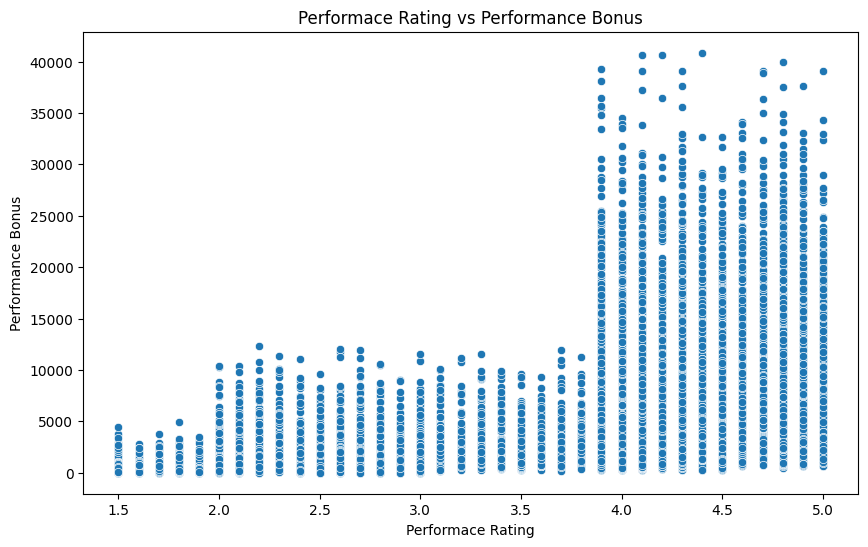

In [ ]:
#Performance Rating vs Bonus
plt.figure(figsize=(10, 6))
sns.scatterplot(
data=hr_data,
x="performace_rating",
y="performance_bonus"
)
plt.title("Performace Rating vs Performance Bonus")
plt.xlabel("Performace Rating")
plt.ylabel("Performance Bonus")
plt.show()

#Employee Demographic Analysis

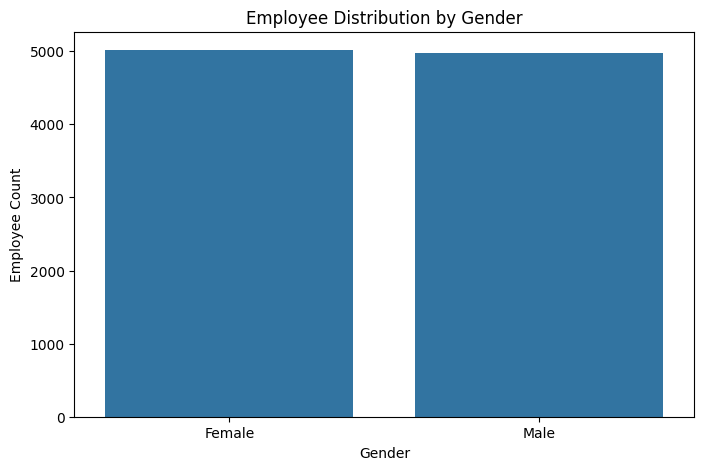

In [ ]:
#Gender Distribution
plt.figure(figsize=(8, 5))
sns.countplot(
data=hr_data,
x="gender"
)
plt.title("Employee Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Employee Count")
plt.show()

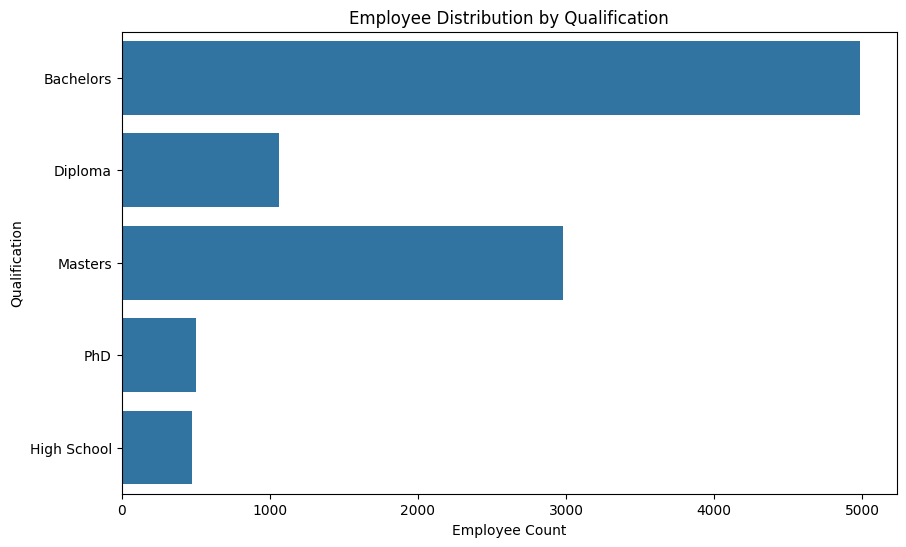

In [ ]:
#Qualification Distribution
plt.figure(figsize=(10, 6))
sns.countplot(
    data=hr_data,
    y="qualification"
)

plt.title("Employee Distribution by Qualification")
plt.xlabel("Employee Count")
plt.ylabel("Qualification")
plt.show()

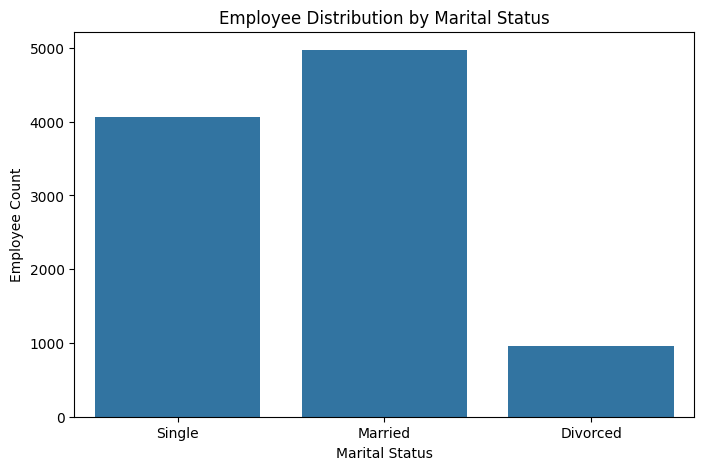

In [ ]:
#Marital Status Distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=hr_data,
    x="marital_status"
)

plt.title("Employee Distribution by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Employee Count")
plt.show()

#Location Analysis

In [ ]:
#Employees by Location
location_analysis = (
    hr_data.groupby("state")
    ["emp_id"]
    .nunique()
    .sort_values(ascending=False)
)

location_analysis

,emp_id
state,
England,2017
Scotland,1331
Tamil Nadu,719
California,691
Delhi,669
Washington,667
Illinois,665
Maharashtra,662
Telangana,654


In [ ]:
#Employees by Location
location_analysis = (
    hr_data.groupby("city")
    ["emp_id"]
    .nunique()
    .sort_values(ascending=False)
)

location_analysis

,emp_id
city,
Chennai,719
Edinburgh,693
Birmingham,693
San Francisco,691
London,680
New Delhi,669
Seattle,667
Chicago,665
Mumbai,662


In [ ]:
#Employees by Location
location_analysis = (
    hr_data.groupby("country")
    ["emp_id"]
    .nunique()
    .sort_values(ascending=False)
)

location_analysis

,emp_id
country,
India,3357
UK,3348
US,3295


In [ ]:
#Average Salary by Location
location_salary = (
    hr_data.groupby("country")
    ["basic_salary"]
    .mean()
    .sort_values(ascending=False)
)

location_salary

,basic_salary
country,
US,79698.409712
UK,79483.428913
India,77926.016533


In [ ]:
#Average Salary by Location
location_salary = (
    hr_data.groupby("state")
    ["basic_salary"]
    .mean()
    .sort_values(ascending=False)
)

location_salary

,basic_salary
state,
New York,81194.485179
Telangana,80616.452599
Washington,80550.952024
England,80351.150223
Maharashtra,79749.690332
Illinois,79710.289474
Texas,79162.083994
Scotland,78168.482344
Tamil Nadu,78028.296245


In [ ]:
#Average Salary by Location
location_salary = (
    hr_data.groupby("city")
    ["basic_salary"]
    .mean()
    .sort_values(ascending=False)
)

location_salary

,basic_salary
city,
London,82016.099265
New York,81194.485179
Hyderabad,80616.452599
Seattle,80550.952024
Manchester,80034.243012
Mumbai,79749.690332
Chicago,79710.289474
Austin,79162.083994
Birmingham,79011.933622


In [ ]:
#Average Performance by Location
location_performance = (
    hr_data.groupby("country")
    ["performace_rating"]
    .mean()
    .sort_values(ascending=False)
)

location_performance

,performace_rating
country,
India,3.791332
US,3.779029
UK,3.776971


In [ ]:
#Average Performance by Location
location_performance = (
    hr_data.groupby("state")
    ["performace_rating"]
    .mean()
    .sort_values(ascending=False)
)

location_performance

,performace_rating
state,
Telangana,3.851376
Texas,3.816799
Karnataka,3.811792
New York,3.803276
England,3.776996
Scotland,3.776935
Washington,3.775112
Delhi,3.774141
Maharashtra,3.769486


In [ ]:
#Average Performance by Location
location_performance = (
    hr_data.groupby("city")
    ["performace_rating"]
    .mean()
    .sort_values(ascending=False)
)

location_performance

,performace_rating
city,
Manchester,3.868634
Hyderabad,3.851376
Edinburgh,3.835642
Austin,3.816799
Bangalore,3.811792
New York,3.803276
Seattle,3.775112
New Delhi,3.774141
Mumbai,3.769486


#Statistical Analysis

In [ ]:
#Salary Statistics
salary_columns = [
    "basic_salary",
    "gross_salary",
    "calculated_net_salary",
    "performance_bonus",
    "total_deductions"
]

hr_data[salary_columns].describe()

,basic_salary,gross_salary,calculated_net_salary,performance_bonus,total_deductions
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,79031.441750,75550.077033,66057.522302,6011.190014,9492.554731
std,45297.012188,44477.662265,39088.650095,6429.342588,5424.047157
min,15000.000000,13087.500000,11175.000000,0.000000,1912.500000
25%,37440.000000,34913.307500,30403.915000,1476.567500,4492.800000
50%,76675.000000,71765.690000,62606.215000,3716.160000,9201.000000
75%,116450.000000,109426.960000,95544.477500,8231.967500,13974.000000
max,190200.000000,207181.800000,184501.800000,40861.800000,22824.000000


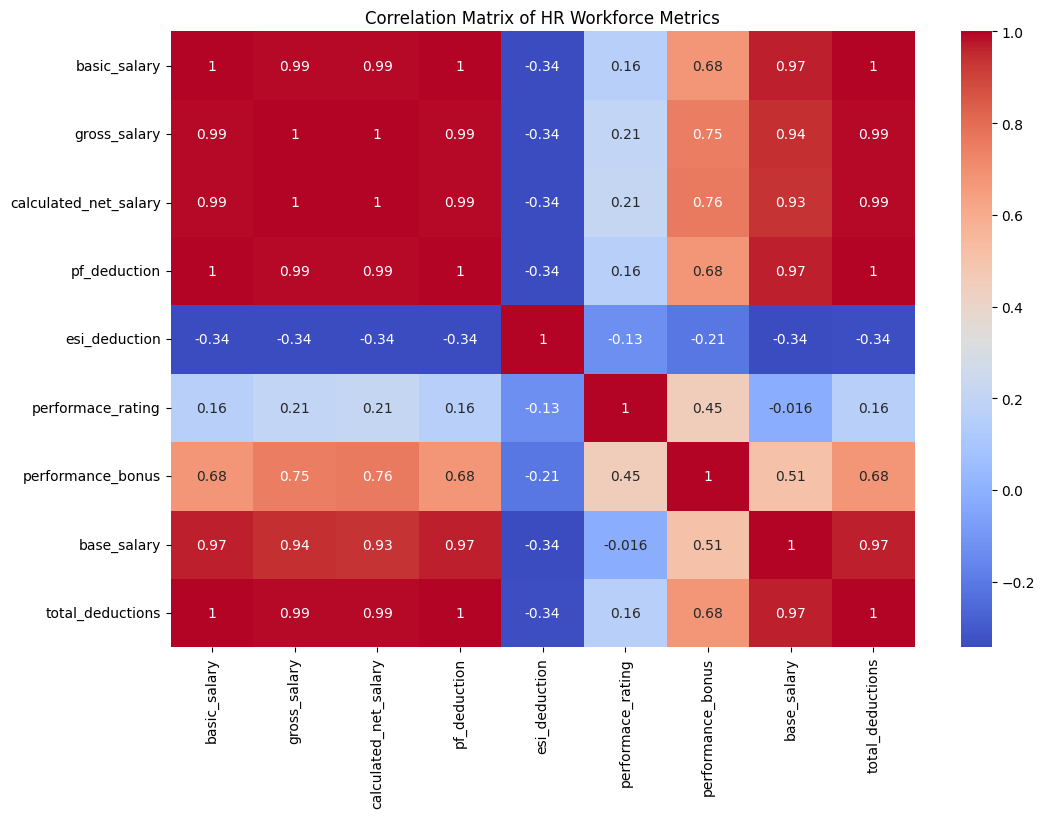

In [ ]:
#Correlation Analysis
numeric_columns = [
    "basic_salary",
    "gross_salary",
    "calculated_net_salary",
    "pf_deduction",
    "esi_deduction",
    "performace_rating",
    "performance_bonus",
    "base_salary",
    "total_deductions"
]

correlation_matrix = hr_data[
    numeric_columns
].corr()

#correlation_matrix Heatmap:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm"
)

plt.title(
    "Correlation Matrix of HR Workforce Metrics"
)

plt.show()